# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

/Users/salehahmed/miniconda3/envs/py311/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 7114.56it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

#### Load bert-base-uncased

In [6]:
from transformers import AutoModel

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert = AutoModel.from_pretrained(bert_name, attn_implementation="eager")  # eager so it can return attention weights
bert.eval()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12927.94it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

#### 1. Layers and attention heads

In [7]:
num_layers = bert.config.num_hidden_layers
num_heads = bert.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)

Transformer layers: 12
Attention heads per layer: 12


#### 2. Total attention heads

In [8]:
total_heads = num_layers * num_heads
print("Total attention heads:", total_heads)

Total attention heads: 144


#### 3. Attention from layer 3, head 2

Python counts from 0, so the third layer is index 2 and the second head is index 1.

In [9]:
sentence = "Transformers use self-attention to understand language."

bert_inputs = bert_tokenizer(sentence, return_tensors="pt")
bert_tokens = bert_tokenizer.convert_ids_to_tokens(bert_inputs["input_ids"][0])
print("Tokens:", bert_tokens)

with torch.no_grad():
    bert_outputs = bert(**bert_inputs, output_attentions=True)

print("Number of attention layers returned:", len(bert_outputs.attentions))
print("Shape of one layer:", bert_outputs.attentions[0].shape)  # (batch, heads, tokens, tokens)

att = bert_outputs.attentions[2][0, 1]
print("Layer 3, head 2 shape:", att.shape)

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']


Number of attention layers returned: 12
Shape of one layer: torch.Size([1, 12, 11, 11])
Layer 3, head 2 shape: torch.Size([11, 11])


In [10]:
import pandas as pd

# rows = token that is looking, columns = token being looked at
att_df = pd.DataFrame(att.numpy(), index=bert_tokens, columns=bert_tokens).round(3)
att_df

,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


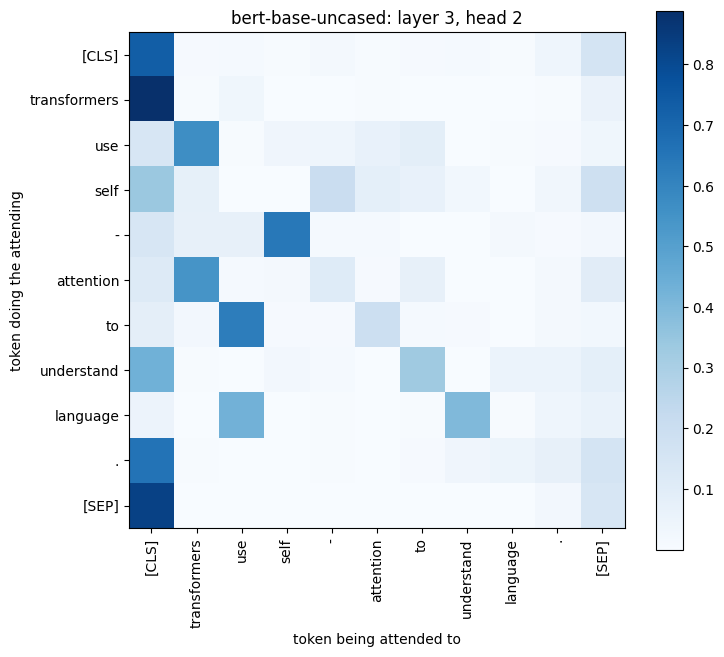

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 7))
plt.imshow(att, cmap="Blues")
plt.xticks(range(len(bert_tokens)), bert_tokens, rotation=90)
plt.yticks(range(len(bert_tokens)), bert_tokens)
plt.colorbar()
plt.title("bert-base-uncased: layer 3, head 2")
plt.xlabel("token being attended to")
plt.ylabel("token doing the attending")
plt.show()

In [12]:
# each row adds up to 1 because of the softmax
print("Row sums:", att.sum(dim=1).round(decimals=3))

# where each token puts most of its attention
for i, tok in enumerate(bert_tokens):
    j = att[i].argmax().item()
    print(f"{tok:>12} -> {bert_tokens[j]:<12} ({att[i, j]:.2f})")

Row sums: tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])
       [CLS] -> [CLS]        (0.73)
transformers -> [CLS]        (0.89)
         use -> transformers (0.57)
        self -> [CLS]        (0.34)
           - -> self         (0.64)
   attention -> transformers (0.54)
          to -> use          (0.62)
  understand -> [CLS]        (0.43)
    language -> use          (0.43)
           . -> [CLS]        (0.66)
       [SEP] -> [CLS]        (0.83)


#### 4. What the rows and columns mean

The matrix is 11 × 11 because the sentence has 11 tokens after tokenization (including `[CLS]` and `[SEP]`, and "self-attention" is split into "self", "-" and "attention").

- **Rows:** each row is one token that is doing the attending (the query). The row shows how much that token looks at every other token when BERT builds its new representation in this layer.
- **Columns:** each column is a token that is being attended to (the key).
- So the value in row *i* and column *j* is how much token *i* pays attention to token *j*. Every row adds up to 1 because of the softmax, as the row sums above show.

In this head a lot of the attention goes to `[CLS]` (for example "transformers" → `[CLS]` 0.89 and `[SEP]` → `[CLS]` 0.83), which BERT often does when a token has nothing specific to look at. Some rows connect words that belong together, like "-" → "self" (0.64), "use" → "transformers" (0.57), "language" → "use" (0.43) and "language" → "understand" (0.40). The matrix is also not symmetric: "use" looks at "transformers" a lot (0.57), but "transformers" barely looks at "use" (0.03).